# Pedido 8 — Verificación de fuga de información en el modelo

Auditoría de variables, predicción de la **hora siguiente** y validación temporal.

Proyecto: Detección temprana de pérdida de paridad de USDC en Binance (Terra, FTX y SVB)

Las tres sospechas del profesor y cómo se comprueban aquí:

1. **Autocorrelación horaria**: la búsqueda de hiperparámetros del notebook 05 usa `StratifiedKFold(3, shuffle=True)`; aquí se reemplaza por bloques de días (`GroupKFold` por fecha), sin barajado.
2. **Variables derivadas de la etiqueta**: se audita la fórmula de cada variable y se mide su correlación de Spearman con `desviacion_paridad`; se hace una prueba de ablación.
3. **Proxy**: todas las métricas se reportan por separado para `USDCUSDT` (dato real) y `BUSDUSDT_proxy`.

Además, el objetivo pasa a ser `severidad_t1` (severidad de la hora t+1) con variables de la hora t. No se tocan los notebooks 04 ni 05, ni los umbrales (0.0011 y 0.0034).

In [1]:
import warnings, sys
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, imblearn, scipy
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, TimeSeriesSplit
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("Reproducibilidad -> semilla:", SEED)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__, "| scipy", scipy.__version__)

Reproducibilidad -> semilla: 42
python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | scipy 1.18.1


## 1. Datos y etiqueta de la hora siguiente

Se parte de `data/features.parquet` (la misma serie del modelo). `severidad_t1` es la severidad de la hora t+1 **solo si la hora t+1 existe exactamente una hora después**: no se desplaza a través de un hueco y esa fila se descarta. Las ventanas de evento son las de los notebooks 03 y 05.

In [2]:
FEATURES = ["volumen_relativo", "spread_btc_usdc_usdt", "volatilidad_ventana"]
CL = ["normal", "alerta", "estres"]
EVENTOS = {"Terra": ("2022-05-07", "2022-05-17"),
           "FTX":   ("2022-11-05", "2022-11-15"),
           "SVB":   ("2023-03-08", "2023-03-18")}
COMBINACIONES = [(["Terra", "SVB"], "FTX"), (["Terra", "FTX"], "SVB"), (["FTX", "SVB"], "Terra")]

serie = pd.read_parquet("../data/features.parquet").sort_values("open_time_ts").reset_index(drop=True)
for c in serie.columns:
    if c != "open_time_ts" and pd.api.types.is_numeric_dtype(serie[c]):
        serie[c] = serie[c].astype("float64")
    elif c != "open_time_ts":
        serie[c] = serie[c].astype(str)
assert len(serie) == 17172

# etiqueta t+1 sin cruzar huecos
paso = serie["open_time_ts"].shift(-1) - serie["open_time_ts"]
continua = paso == pd.Timedelta(hours=1)
serie["severidad_t1"] = serie["severidad"].shift(-1).where(continua)
serie["fuente_t1"] = serie["fuente_paridad"].shift(-1).where(continua)
serie["fecha"] = serie["open_time_ts"].dt.strftime("%Y-%m-%d")

print("Filas de la serie sin hora t+1 (hueco o última hora):", int((~continua).sum()))
print(serie.loc[~continua, ["open_time_ts", "fuente_paridad", "severidad"]].to_string(index=False))

def ventana(nombre):
    a, b = EVENTOS[nombre]
    return serie[(serie.open_time_ts >= a) & (serie.open_time_ts <= b)]

filas = []
datos = {}
for ev in EVENTOS:
    w = ventana(ev)
    sin_feat = w[FEATURES].isna().any(axis=1)
    sin_t1 = w["severidad_t1"].isna()
    ok = w[~sin_feat & ~sin_t1].copy()
    datos[ev] = ok
    filas.append({"evento": ev, "horas_con_dato_en_ventana": len(w),
                  "descartadas_por_variables_nulas": int(sin_feat.sum()),
                  "descartadas_solo_por_falta_de_t+1": int((~sin_feat & sin_t1).sum()),
                  "filas_usadas": len(ok),
                  "real": int((ok.fuente_paridad == "USDCUSDT").sum()),
                  "proxy": int((ok.fuente_paridad == "BUSDUSDT_proxy").sum())})
resumen_filas = pd.DataFrame(filas)
resumen_filas

Filas de la serie sin hora t+1 (hueco o última hora): 5
       open_time_ts fuente_paridad severidad
2022-09-26 02:00:00       USDCUSDT    normal
2023-02-28 23:00:00 BUSDUSDT_proxy    normal
2023-03-10 23:00:00 BUSDUSDT_proxy    alerta
2023-03-24 12:00:00       USDCUSDT    alerta
2023-12-31 23:00:00       USDCUSDT    normal


,evento,horas_con_dato_en_ventana,descartadas_por_variables_nulas,descartadas_solo_por_falta_de_t+1,filas_usadas,real,proxy
0,Terra,241,0,0,241,241,0
1,FTX,241,0,0,241,0,241
2,SVB,179,16,1,162,139,23


In [3]:
# Distribución de la etiqueta t+1 por evento
for ev, d in datos.items():
    print(ev, d["severidad_t1"].value_counts().reindex(CL, fill_value=0).to_dict())

Terra {'normal': 108, 'alerta': 111, 'estres': 22}
FTX {'normal': 106, 'alerta': 122, 'estres': 13}
SVB {'normal': 20, 'alerta': 52, 'estres': 90}


## 2. Auditoría de variables (paso 1)

Fórmulas **tal como están en `notebooks/04_features.ipynb`**:

| Variable | Fórmula exacta | Serie que usa | Ventana | ¿Usa la hora actual (t)? | ¿Usa precio de USDCUSDT / BUSDUSDT? |
|---|---|---|---|---|---|
| `volumen_relativo` | `volume_t / rolling(24, min_periods=1).mean(volume)` | `volume` de USDCUSDT o de BUSDUSDT (proxy), según la hora | 24 filas consecutivas (por posición, no por reloj), incluye t | Sí | Usa el **volumen** del par de paridad, no su precio |
| `spread_btc_usdc_usdt` | `(close_BTCUSDC − close_BTCUSDT) / close_BTCUSDT` (BTCBUSD si es proxy) | `close` de BTCUSDC (o BTCBUSD) y de BTCUSDT, misma hora | Sin ventana (misma hora t) | Sí | **No usa USDCUSDT directamente, pero el cociente BTCUSDC/BTCUSDT equivale a ≈ 1/(precio USDC/USDT)**: es casi el mismo precio que define la etiqueta |
| `volatilidad_ventana` | `rolling(24, min_periods=2).std(pct_change(close_BTCUSDT))` | `close` de **BTCUSDT** (contexto de mercado) | 24 filas consecutivas (por posición), incluye t | Sí | No usa el precio de USDCUSDT ni de BUSDUSDT |

La etiqueta `severidad` sale de `desviacion_paridad = |close_USDCUSDT − 1|` (o BUSDUSDT en el proxy), con umbrales 0.0011 y 0.0034. La siguiente celda comprueba numéricamente la sospecha sobre el spread.

In [4]:
s = serie.copy()
s["dev_firmada"] = s["close"] - 1.0
m = s["spread_btc_usdc_usdt"].notna()
print("Pearson(spread, −(close−1)) en toda la serie:", round(np.corrcoef(s.loc[m, "spread_btc_usdc_usdt"], -s.loc[m, "dev_firmada"])[0, 1], 4))
print("Equivalencia teórica: BTCUSDC/BTCUSDT ≈ 1/(USDCUSDT)  ->  spread ≈ 1/P − 1 ≈ −(P − 1)")
cmp = s.loc[m, ["open_time_ts", "close", "spread_btc_usdc_usdt"]].copy()
cmp["−(close−1)"] = -(cmp["close"] - 1)
cmp.sample(6, random_state=SEED).sort_values("open_time_ts")

Pearson(spread, −(close−1)) en toda la serie: 0.9936
Equivalencia teórica: BTCUSDC/BTCUSDT ≈ 1/(USDCUSDT)  ->  spread ≈ 1/P − 1 ≈ −(P − 1)


,open_time_ts,close,spread_btc_usdc_usdt,−(close−1)
4993,2022-07-28 01:00:00,0.9998,0.000143,0.0002
5771,2022-08-29 11:00:00,1.0000,-0.000128,-0.0000
9085,2023-01-19 10:00:00,1.0000,-0.000035,-0.0000
9414,2023-02-02 03:00:00,0.9998,0.000232,0.0002
11947,2023-05-28 07:00:00,0.9998,0.000129,0.0002
12290,2023-06-11 14:00:00,0.9995,0.000526,0.0005


## 3. Correlación de Spearman con `desviacion_paridad` (paso 2)

Misma hora, por evento (ventana del EDA) y en toda la serie. Como `desviacion_paridad` es un valor absoluto y el spread tiene signo, se añade la fila `|spread|` para no subestimar el parecido: si el spread cambia de signo según el sentido de la desviación, la correlación firmada subestima la relación.

In [5]:
def rho(x, y):
    mk = x.notna() & y.notna()
    return round(float(spearmanr(x[mk], y[mk])[0]), 3)

conj = {"Total (17 172 h)": serie}
for ev in EVENTOS:
    conj[f"{ev} (ventana EDA)"] = ventana(ev)
filas = []
for nom, w in conj.items():
    w = w.copy(); w["abs_spread"] = w["spread_btc_usdc_usdt"].abs()
    filas.append({"conjunto": nom, "n": len(w),
                  "volumen_relativo": rho(w["volumen_relativo"], w["desviacion_paridad"]),
                  "spread_btc_usdc_usdt": rho(w["spread_btc_usdc_usdt"], w["desviacion_paridad"]),
                  "|spread| (extra)": rho(w["abs_spread"], w["desviacion_paridad"]),
                  "volatilidad_ventana": rho(w["volatilidad_ventana"], w["desviacion_paridad"])})
spearman = pd.DataFrame(filas)
spearman

,conjunto,n,volumen_relativo,spread_btc_usdc_usdt,|spread| (extra),volatilidad_ventana
0,Total (17 172 h),17172,0.016,-0.021,0.852,0.160
1,Terra (ventana EDA),241,-0.166,-0.917,0.913,0.550
2,FTX (ventana EDA),241,-0.230,-0.898,0.968,0.521
3,SVB (ventana EDA),179,-0.204,0.983,0.984,-0.067


In [6]:
# Marca de |rho| > 0.8
umbral = 0.8
for _, r in spearman.iterrows():
    altas = [c for c in ["volumen_relativo", "spread_btc_usdc_usdt", "|spread| (extra)", "volatilidad_ventana"] if abs(r[c]) > umbral]
    print(f"{r['conjunto']:22s} |rho|>0.8: {altas if altas else 'ninguna'}")

Total (17 172 h)       |rho|>0.8: ['|spread| (extra)']
Terra (ventana EDA)    |rho|>0.8: ['spread_btc_usdc_usdt', '|spread| (extra)']
FTX (ventana EDA)      |rho|>0.8: ['spread_btc_usdc_usdt', '|spread| (extra)']
SVB (ventana EDA)      |rho|>0.8: ['spread_btc_usdc_usdt', '|spread| (extra)']


## 4. Esquema de validación temporal (paso 4)

Se mantiene la validación **entre eventos** (entrenar con dos, validar con el tercero). Dentro del entrenamiento, el barajado se reemplaza por `GroupKFold(3)` con grupos = **fecha** de cada hora (bloques de días completos, sin barajar, sin mezclar horas de un mismo día entre entrenamiento y validación interna). SMOTE y el escalador viven **dentro** del `Pipeline` de `imblearn`, así que se ajustan solo con el entrenamiento de cada partición.

Se probó primero `TimeSeriesSplit(gap=24)`: la siguiente celda muestra por qué no es viable con estos datos.

In [7]:
ents = pd.concat([datos["Terra"], datos["SVB"]]).sort_values("open_time_ts")   # ejemplo: entrenar con Terra+SVB
tss = TimeSeriesSplit(n_splits=3, gap=24)
for i, (tr, te) in enumerate(tss.split(ents), 1):
    print(f"Fold {i}: entrenamiento={len(tr)} filas {ents['severidad_t1'].iloc[tr].value_counts().to_dict()} | "
          f"validación={len(te)} filas {ents['severidad_t1'].iloc[te].value_counts().to_dict()}")
print("-> en el fold 1 el entrenamiento solo tiene 'normal': ni SMOTE ni el random forest pueden aprender alerta/estrés.")

Fold 1: entrenamiento=79 filas {'normal': 79} | validación=100 filas {'alerta': 73, 'estres': 22, 'normal': 5}
Fold 2: entrenamiento=179 filas {'normal': 108, 'alerta': 49, 'estres': 22} | validación=100 filas {'alerta': 41, 'estres': 39, 'normal': 20}
Fold 3: entrenamiento=279 filas {'normal': 128, 'alerta': 114, 'estres': 37} | validación=100 filas {'estres': 51, 'alerta': 49}
-> en el fold 1 el entrenamiento solo tiene 'normal': ni SMOTE ni el random forest pueden aprender alerta/estrés.


In [8]:
class SMOTEAdaptativo(SMOTE):
    """SMOTE con k_neighbors ajustado al tamaño de la clase minoritaria de cada partición."""
    def fit_resample(self, X, y):
        n_min = pd.Series(y).value_counts().min()
        if n_min < 2:
            return X, y
        self.k_neighbors = int(max(1, min(5, n_min - 1)))
        return super().fit_resample(X, y)

GRID_RF = {"clf__max_depth": [3, 4, 6], "clf__n_estimators": [100, 200]}

def metricas(y, p):
    y = np.asarray(y, dtype=object); p = np.asarray(p, dtype=object)
    if len(y) == 0:   # p. ej. FTX no tiene filas de dato real
        return {"n": 0, "n_alerta": 0, "n_estres": 0, "f1_normal": np.nan, "f1_alerta": np.nan,
                "f1_estres": np.nan, "f1_macro": np.nan, "recall_estres": np.nan}
    sup = {c: int((y == c).sum()) for c in CL}
    f = f1_score(y, p, labels=CL, average=None, zero_division=0)
    f1 = {c: (np.nan if sup[c] == 0 else float(f[i])) for i, c in enumerate(CL)}
    rec = np.nan if sup["estres"] == 0 else float(((y == "estres") & (p == "estres")).sum() / sup["estres"])
    return {"n": len(y), "n_alerta": sup["alerta"], "n_estres": sup["estres"],
            "f1_normal": f1["normal"], "f1_alerta": f1["alerta"], "f1_estres": f1["estres"],
            "f1_macro": float(np.nanmean(list(f1.values()))) if len(y) else np.nan, "recall_estres": rec}

def split(entrenar, validar, feats, objetivo):
    tr = pd.concat([datos[e] for e in entrenar]).sort_values("open_time_ts")
    va = datos[validar].sort_values("open_time_ts")
    return tr, va

def rf_smote_temporal(tr, va, feats, objetivo):
    pipe = ImbPipeline([("sc", StandardScaler()), ("sm", SMOTEAdaptativo(random_state=SEED)),
                        ("clf", RandomForestClassifier(random_state=SEED))])
    X, y, g = tr[feats].to_numpy(float), tr[objetivo].to_numpy(object), tr["fecha"].to_numpy()
    cv = list(GroupKFold(n_splits=3).split(X, y, g))
    gs = GridSearchCV(pipe, GRID_RF, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X, y)
    return gs.predict(va[feats].to_numpy(float)), gs.best_params_

def rf_smote_original(tr, va, feats, objetivo):
    # Reproduce el procedimiento del notebook 05: escalar y SMOTE ANTES de partir + StratifiedKFold con barajado
    sc = StandardScaler(); X = sc.fit_transform(tr[feats].to_numpy(float)); y = tr[objetivo].to_numpy(object)
    k = max(1, min(5, pd.Series(y).value_counts().min() - 1))
    X, y = SMOTE(random_state=SEED, k_neighbors=k).fit_resample(X, y)
    pipe = Pipeline([("clf", RandomForestClassifier(random_state=SEED))])
    gs = GridSearchCV(pipe, GRID_RF, scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1).fit(X, y)
    return gs.predict(sc.transform(va[feats].to_numpy(float))), gs.best_params_

def logistica_base(tr, va, feats, objetivo):
    sc = StandardScaler(); X = sc.fit_transform(tr[feats].to_numpy(float))
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X, tr[objetivo].to_numpy(object))
    return m.predict(sc.transform(va[feats].to_numpy(float))), {"C": 1.0}

print("Funciones listas")

Funciones listas


## 5. Modelos sobre la hora siguiente (pasos 3, 5 y 7)

Modelos: **persistencia** (`severidad_t1 = severidad_t`), **clase mayoritaria** (siempre normal), **logística** del modelo base (C=1, `class_weight="balanced"`) y **random forest + SMOTE** con la rejilla del modelo definitivo y validación temporal.

In [9]:
res, preds, params = [], {}, []

def registrar(modelo, combo, va, pred, objetivo="severidad_t1", extra=None):
    y = va[objetivo].to_numpy(object)
    for fuente, mask in [("todas", np.ones(len(va), bool)),
                         ("real (USDCUSDT)", (va["fuente_paridad"] == "USDCUSDT").to_numpy()),
                         ("proxy (BUSDUSDT)", (va["fuente_paridad"] == "BUSDUSDT_proxy").to_numpy())]:
        r = {"combinacion": combo, "modelo": modelo, "fuente": fuente}
        r.update(metricas(y[mask], np.asarray(pred, dtype=object)[mask]))
        if extra: r.update(extra)
        res.append(r)

for entrenar, validar in COMBINACIONES:
    combo = f"{'+'.join(entrenar)} -> {validar}"
    tr, va = split(entrenar, validar, FEATURES, "severidad_t1")
    registrar("persistencia", combo, va, va["severidad"].to_numpy(object)); preds[(combo, "persistencia")] = (va["severidad_t1"].to_numpy(object), va["severidad"].to_numpy(object))
    registrar("mayoritaria", combo, va, np.array(["normal"] * len(va), dtype=object)); preds[(combo, "mayoritaria")] = (va["severidad_t1"].to_numpy(object), np.array(["normal"] * len(va), dtype=object))
    p, hp = logistica_base(tr, va, FEATURES, "severidad_t1"); registrar("logistica", combo, va, p); preds[(combo, "logistica")] = (va["severidad_t1"].to_numpy(object), p); params.append({"combinacion": combo, "modelo": "logistica", **hp})
    p, hp = rf_smote_temporal(tr, va, FEATURES, "severidad_t1"); registrar("rf_smote", combo, va, p); preds[(combo, "rf_smote")] = (va["severidad_t1"].to_numpy(object), p); params.append({"combinacion": combo, "modelo": "rf_smote", **hp})

res = pd.DataFrame(res)
tabla_total = res[res.fuente == "todas"].drop(columns="fuente")
tabla_total.round(3)

,combinacion,modelo,n,n_alerta,n_estres,f1_normal,f1_alerta,f1_estres,f1_macro,recall_estres
0,Terra+SVB -> FTX,persistencia,241,122,13,0.995,0.979,0.846,0.940,0.846
3,Terra+SVB -> FTX,mayoritaria,241,122,13,0.611,0.000,0.000,0.204,0.000
6,Terra+SVB -> FTX,logistica,241,122,13,0.675,0.412,0.067,0.384,0.154
9,Terra+SVB -> FTX,rf_smote,241,122,13,0.986,0.945,0.267,0.732,0.154
12,Terra+FTX -> SVB,persistencia,162,52,90,0.976,0.922,0.961,0.953,0.967
15,Terra+FTX -> SVB,mayoritaria,162,52,90,0.220,0.000,0.000,0.073,0.000
18,Terra+FTX -> SVB,logistica,162,52,90,0.220,0.000,0.000,0.073,0.000
21,Terra+FTX -> SVB,rf_smote,162,52,90,0.220,0.000,0.000,0.073,0.000
24,FTX+SVB -> Terra,persistencia,241,111,22,0.986,0.959,0.864,0.936,0.864
27,FTX+SVB -> Terra,mayoritaria,241,111,22,0.619,0.000,0.000,0.206,0.000


In [10]:
# Mismas métricas separadas por fuente de la hora t (real vs proxy)
tabla_fuente = res[res.fuente != "todas"].round(3)
tabla_fuente

,combinacion,modelo,fuente,n,n_alerta,n_estres,f1_normal,f1_alerta,f1_estres,f1_macro,recall_estres
1,Terra+SVB -> FTX,persistencia,real (USDCUSDT),0,0,0,NaN,NaN,NaN,NaN,NaN
2,Terra+SVB -> FTX,persistencia,proxy (BUSDUSDT),241,122,13,0.995,0.979,0.846,0.940,0.846
4,Terra+SVB -> FTX,mayoritaria,real (USDCUSDT),0,0,0,NaN,NaN,NaN,NaN,NaN
5,Terra+SVB -> FTX,mayoritaria,proxy (BUSDUSDT),241,122,13,0.611,0.000,0.000,0.204,0.000
7,Terra+SVB -> FTX,logistica,real (USDCUSDT),0,0,0,NaN,NaN,NaN,NaN,NaN
8,Terra+SVB -> FTX,logistica,proxy (BUSDUSDT),241,122,13,0.675,0.412,0.067,0.384,0.154
10,Terra+SVB -> FTX,rf_smote,real (USDCUSDT),0,0,0,NaN,NaN,NaN,NaN,NaN
11,Terra+SVB -> FTX,rf_smote,proxy (BUSDUSDT),241,122,13,0.986,0.945,0.267,0.732,0.154
13,Terra+FTX -> SVB,persistencia,real (USDCUSDT),139,49,90,NaN,0.928,0.961,0.945,0.967
14,Terra+FTX -> SVB,persistencia,proxy (BUSDUSDT),23,3,0,0.976,0.800,NaN,0.888,NaN


In [11]:
# Hiperparámetros elegidos por combinación
tabla_params = pd.DataFrame(params)
tabla_params

,combinacion,modelo,C,clf__max_depth,clf__n_estimators
0,Terra+SVB -> FTX,logistica,1.0,NaN,NaN
1,Terra+SVB -> FTX,rf_smote,NaN,6.0,200.0
2,Terra+FTX -> SVB,logistica,1.0,NaN,NaN
3,Terra+FTX -> SVB,rf_smote,NaN,6.0,200.0
4,FTX+SVB -> Terra,logistica,1.0,NaN,NaN
5,FTX+SVB -> Terra,rf_smote,NaN,6.0,100.0


## 6. ¿De dónde venía el salto? Descomposición por pasos y ablación (paso 6)

Se parte del procedimiento original (etiqueta de la hora t, SMOTE antes de partir, `StratifiedKFold` con barajado) y se cambia **un solo paso a la vez** en el random forest + SMOTE. Todas las filas usadas son las mismas (las que tienen hora t+1), para que la comparación sea limpia.

- **A. Original**: etiqueta hora t, SMOTE antes de partir, barajado.
- **B. Validación temporal**: etiqueta hora t, SMOTE dentro del Pipeline, `GroupKFold` por fecha.
- **C. Hora siguiente**: etiqueta t+1 (lo que se reporta en la sección 5).
- **Ablación** (sobre B y C): sin `spread_btc_usdc_usdt`, sin `volatilidad_ventana`, y solo con `volumen_relativo`.

In [12]:
FEATS_SIN_SPREAD = [f for f in FEATURES if f != "spread_btc_usdc_usdt"]
FEATS_SIN_VOL = [f for f in FEATURES if f != "volatilidad_ventana"]
FEATS_SOLO_VOLREL = ["volumen_relativo"]

paso_res = []
def correr(nombre, funcion, feats, objetivo):
    for entrenar, validar in COMBINACIONES:
        combo = f"{'+'.join(entrenar)} -> {validar}"
        tr, va = split(entrenar, validar, feats, objetivo)
        p, hp = funcion(tr, va, feats, objetivo)
        r = {"paso": nombre, "combinacion": combo, "hiperparametros": f"prof={hp.get('clf__max_depth')}, arboles={hp.get('clf__n_estimators')}"}
        r.update(metricas(va[objetivo].to_numpy(object), p))
        paso_res.append(r)

correr("A. original (hora t, barajado, SMOTE antes)", rf_smote_original, FEATURES, "severidad")
correr("B. hora t, validación temporal", rf_smote_temporal, FEATURES, "severidad")
correr("B sin spread", rf_smote_temporal, FEATS_SIN_SPREAD, "severidad")
correr("B sin volatilidad", rf_smote_temporal, FEATS_SIN_VOL, "severidad")
correr("B solo volumen_relativo", rf_smote_temporal, FEATS_SOLO_VOLREL, "severidad")
correr("C. hora siguiente t+1", rf_smote_temporal, FEATURES, "severidad_t1")
correr("C sin spread", rf_smote_temporal, FEATS_SIN_SPREAD, "severidad_t1")
correr("C sin volatilidad", rf_smote_temporal, FEATS_SIN_VOL, "severidad_t1")
correr("C solo volumen_relativo", rf_smote_temporal, FEATS_SOLO_VOLREL, "severidad_t1")
pasos = pd.DataFrame(paso_res)
pasos[["paso", "combinacion", "hiperparametros", "f1_normal", "f1_alerta", "f1_estres", "f1_macro", "recall_estres"]].round(3)

,paso,combinacion,hiperparametros,f1_normal,f1_alerta,f1_estres,f1_macro,recall_estres
0,"A. original (hora t, barajado, SMOTE antes)",Terra+SVB -> FTX,"prof=6, arboles=100",0.991,0.949,0.267,0.735,0.154
1,"A. original (hora t, barajado, SMOTE antes)",Terra+FTX -> SVB,"prof=6, arboles=100",0.230,0.000,0.000,0.077,0.000
2,"A. original (hora t, barajado, SMOTE antes)",FTX+SVB -> Terra,"prof=6, arboles=100",0.898,0.885,0.857,0.880,0.818
3,"B. hora t, validación temporal",Terra+SVB -> FTX,"prof=6, arboles=100",0.991,0.949,0.267,0.735,0.154
4,"B. hora t, validación temporal",Terra+FTX -> SVB,"prof=6, arboles=100",0.230,0.000,0.000,0.077,0.000
5,"B. hora t, validación temporal",FTX+SVB -> Terra,"prof=6, arboles=100",0.898,0.885,0.857,0.880,0.818
6,B sin spread,Terra+SVB -> FTX,"prof=6, arboles=100",0.550,0.416,0.000,0.322,0.000
7,B sin spread,Terra+FTX -> SVB,"prof=3, arboles=200",0.114,0.317,0.000,0.144,0.000
8,B sin spread,FTX+SVB -> Terra,"prof=4, arboles=200",0.346,0.509,0.000,0.285,0.000
9,B sin volatilidad,Terra+SVB -> FTX,"prof=6, arboles=200",0.995,0.988,0.917,0.967,0.846


In [13]:
# ¿Cambió algo al pasar del barajado (A) a bloques de días (B)?  Se comparan hiperparámetros elegidos y F1
a = pasos[pasos.paso.str.startswith("A.")].set_index("combinacion")
b = pasos[pasos.paso.str.startswith("B. hora t")].set_index("combinacion")
comp = pd.DataFrame({"hiperparametros_A": a["hiperparametros"], "hiperparametros_B": b["hiperparametros"],
                     "F1_estres_A": a["f1_estres"].round(3), "F1_estres_B": b["f1_estres"].round(3)})
comp["mismos_hiperparametros"] = comp["hiperparametros_A"] == comp["hiperparametros_B"]
comp

,hiperparametros_A,hiperparametros_B,F1_estres_A,F1_estres_B,mismos_hiperparametros
combinacion,,,,,
Terra+SVB -> FTX,"prof=6, arboles=100","prof=6, arboles=100",0.267,0.267,True
Terra+FTX -> SVB,"prof=6, arboles=100","prof=6, arboles=100",0.000,0.000,True
FTX+SVB -> Terra,"prof=6, arboles=100","prof=6, arboles=100",0.857,0.857,True


In [14]:
# Resumen: F1 macro promedio de las tres combinaciones por paso
pasos.groupby("paso", sort=False)[["f1_alerta", "f1_estres", "f1_macro", "recall_estres"]].mean().round(3)

,f1_alerta,f1_estres,f1_macro,recall_estres
paso,,,,
"A. original (hora t, barajado, SMOTE antes)",0.611,0.375,0.564,0.324
"B. hora t, validación temporal",0.611,0.375,0.564,0.324
B sin spread,0.414,0.000,0.250,0.000
B sin volatilidad,0.639,0.609,0.657,0.585
B solo volumen_relativo,0.370,0.164,0.311,0.192
C. hora siguiente t+1,0.612,0.271,0.533,0.188
C sin spread,0.426,0.000,0.253,0.000
C sin volatilidad,0.626,0.538,0.627,0.499
C solo volumen_relativo,0.382,0.196,0.326,0.326


In [15]:
# Mismo resumen para los modelos de la sección 5 (hora siguiente)
tabla_total.groupby("modelo", sort=False)[["f1_alerta", "f1_estres", "f1_macro", "recall_estres"]].mean().round(3)

,f1_alerta,f1_estres,f1_macro,recall_estres
modelo,,,,
persistencia,0.953,0.890,0.943,0.892
mayoritaria,0.000,0.000,0.161,0.000
logistica,0.354,0.046,0.301,0.066
rf_smote,0.612,0.271,0.533,0.188


## 7. Matrices de confusión del mejor modelo (paso 8)

Se elige el modelo con mayor F1 macro promedio en las tres combinaciones (sección 5).

F1 macro promedio por modelo: {'persistencia': 0.943, 'rf_smote': 0.533, 'logistica': 0.301, 'mayoritaria': 0.161}
Mejor modelo aprendido: rf_smote | referencia a batir: persistencia


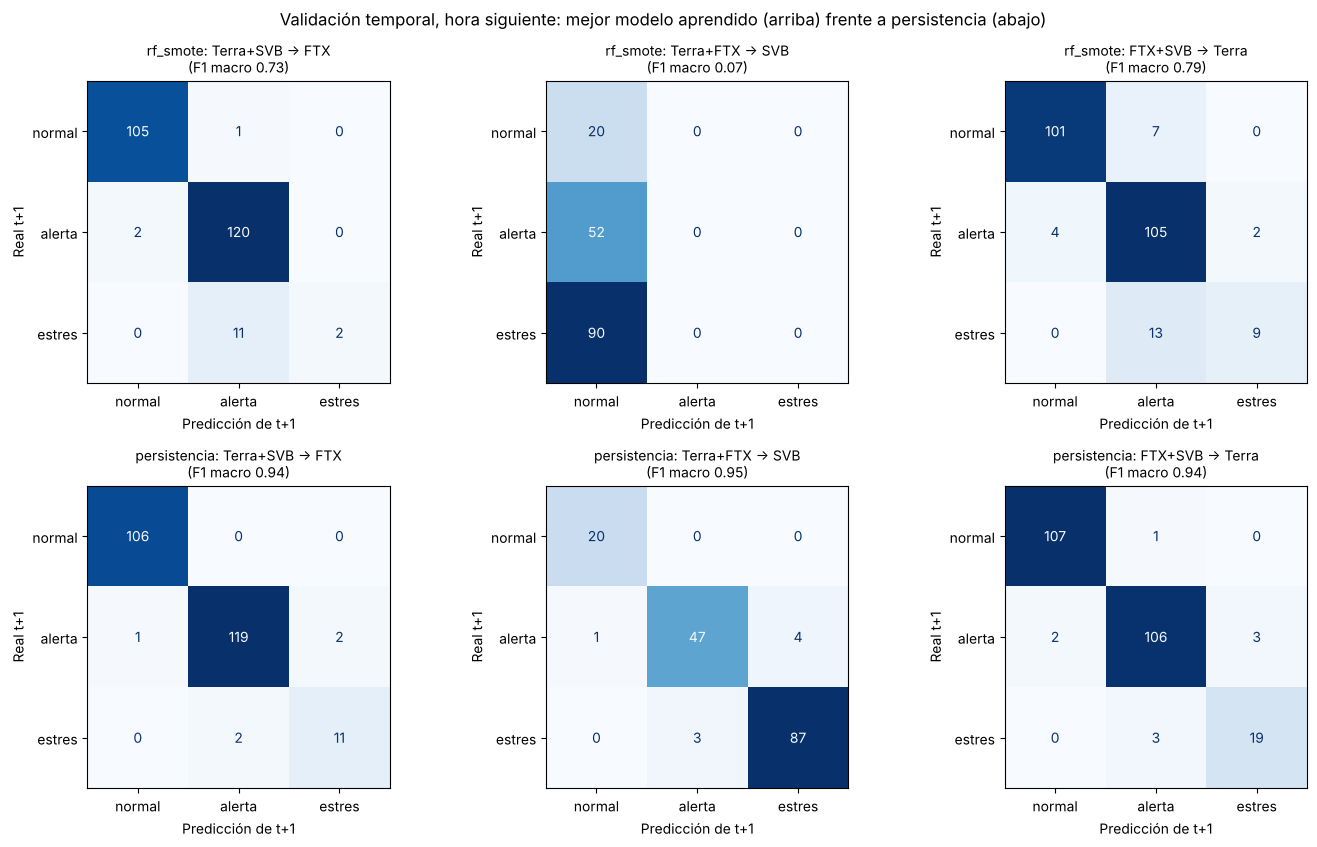

In [16]:
prom = tabla_total.groupby("modelo")["f1_macro"].mean().sort_values(ascending=False)
print("F1 macro promedio por modelo:", prom.round(3).to_dict())
aprendidos = prom.drop(["persistencia", "mayoritaria"])
mejor_modelo = aprendidos.index[0]
print("Mejor modelo aprendido:", mejor_modelo, "| referencia a batir: persistencia")

fig, axes = plt.subplots(2, 3, figsize=(14, 8.6))
for fila, nombre_modelo in enumerate([mejor_modelo, "persistencia"]):
    for ax, (entrenar, validar) in zip(axes[fila], COMBINACIONES):
        combo = f"{'+'.join(entrenar)} -> {validar}"
        y, p = preds[(combo, nombre_modelo)]
        cm = confusion_matrix(y, p, labels=CL)
        ConfusionMatrixDisplay(cm, display_labels=CL).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
        f1m = tabla_total[(tabla_total.combinacion == combo) & (tabla_total.modelo == nombre_modelo)].f1_macro.iloc[0]
        ax.set_title(f"{nombre_modelo}: {combo}\n(F1 macro {f1m:.2f})", fontsize=10)
        ax.set_xlabel("Predicción de t+1"); ax.set_ylabel("Real t+1")
fig.suptitle("Validación temporal, hora siguiente: mejor modelo aprendido (arriba) frente a persistencia (abajo)", fontsize=12)
plt.tight_layout()
plt.savefig("../informe/fig_matrices_validacion_temporal.png", dpi=150)
plt.show()

## 8. Conclusión (paso 11)

**¿Había fuga? Sí, y viene de una variable: `spread_btc_usdc_usdt`.**

- Esa variable es, casi, la propia etiqueta: BTCUSDC/BTCUSDT equivale a ≈ 1/(precio USDC/USDT). Su Pearson con −(close−1) es 0.994 y su Spearman con `desviacion_paridad` es de 0.90 a 0.98 (en valor absoluto) en los tres eventos.
- Ablación: al quitar solo el spread, el F1 de estrés cae a 0.000 en las tres combinaciones (F1 macro promedio de 0.564 a 0.250 con la etiqueta de la hora t, y de 0.533 a 0.253 con la hora siguiente). Al quitar `volatilidad_ventana` no cae.
- **No** es la autocorrelación de la búsqueda de hiperparámetros: pasar de barajado a bloques de días no cambió ningún resultado de la validación entre eventos (ver la celda de comparación A vs B). La validación entre eventos ya era fuera de muestra.
- **Predicción de la hora siguiente:** el random forest + SMOTE (F1 macro 0.533) no supera a la persistencia (0.943) en ninguna de las tres combinaciones, y la logística queda en 0.301. El modelo no anticipa: lee la severidad actual a través del spread.
- **Proxy:** FTX es 100 % `BUSDUSDT_proxy` (su resultado mide el sustituto), Terra es 100 % dato real y SVB mezcla 139 horas reales con 23 de proxy.